# Phase 6 - Advanced tabular model training

This notebook tests whether advanced tabular models beat the best Phase 5 baseline (CatBoost, full feature set) on the **same rows, the same features and the same validation period**, judged mainly by business cost and abusive-class detection, not accuracy.

- **TabPFN** is run when the `tabpfn` package and its pretrained weights are available (`pip install tabpfn`; the first run downloads weights). If either is missing, or the run would exceed the time budget, the limitation is recorded and the rest of the notebook still runs.
- **Robust gradient boosting** uses LightGBM in three fixed configurations: plain regularised, class-weighted, and robust (class-weighted plus stronger regularisation and randomised splits against noisy labels). XGBoost is used only if installed; it is not required.
- **CatBoost** is not retrained: the Phase 5 results and predictions are reused from `reports/phase5_*` (they use the identical split and features).
- No ensemble (Phase 7), no use of July-September labels, no selection by accuracy.

**How to run:** keep this file in `FULL_CODE/notebooks/`, run Phase 5 first (it writes the files reused here), and use the project environment. About 5 minutes without TabPFN; TabPFN on a CPU can add 10-30 minutes (controlled by the budget settings in section 5).

In [1]:
import importlib.util
import json
import platform
import sys
import time
from pathlib import Path

for candidate_path in (Path('../src'), Path('src')):
    if candidate_path.exists():
        sys.path.insert(0, str(candidate_path.resolve()))

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import average_precision_score

from r2sorter.advanced import fit_lgbm, importance_table, measure
from r2sorter.baselines import predict_full
from r2sorter.calibration import AbuseCalibrator
from r2sorter.config import load_config
from r2sorter.data import LABELS, load_all
from r2sorter.fairness import audit
from r2sorter.nlp import classification_report
from r2sorter.protocol import build_protocol
from r2sorter.router import route
from r2sorter.baselines import business_cost
from r2sorter.scoring import official_score

pd.set_option('display.width', 220, 'display.max_columns', 50, 'display.max_colwidth', 70)
SEEDS = (0, 1)
AB = LABELS.index('abusive')
cfg = load_config()
data = load_all(cfg)
REPORTS = Path('../reports') if Path('../reports').exists() else Path('reports')
MODELS = REPORTS.parent / 'models' / 'phase6'
FIG = REPORTS / 'figures'
for folder in (REPORTS, MODELS, FIG):
    folder.mkdir(parents=True, exist_ok=True)
versions = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'scikit-learn': sklearn.__version__, 'lightgbm': lgb.__version__}
print(versions)

{'python': '3.13.17', 'numpy': '2.5.4', 'pandas': '3.1.0', 'scikit-learn': '1.9.1', 'lightgbm': '4.7.0'}


## 1. Data and class distribution
Same protocol as Phase 5: Phase 2 chronological 70/10/20 split (train fits models, calibration fits only the calibrator, test = May-June validation period), preprocessing fitted on train only, Phase 4 text scores rolling-origin out-of-fold for train rows.

In [2]:
protocol = build_protocol(cfg, data)
parts, y_idx, y_abuse = protocol.parts, protocol.y_index, protocol.y_abuse
print('rolling-origin text-score check:', protocol.rolling_check)
distribution = pd.concat({name: parts[name]['label'].value_counts().reindex(LABELS) for name in ('train', 'calibration', 'test')}, axis=1)
share = (distribution / distribution.sum()).round(4)
pd.concat({'count': distribution, 'share': share}, axis=1)

rolling-origin text-score check: {'rows': 30183, 'rolling_rows': 20386, 'grouped_initial_rows': 9797, 'rows_without_kind': 0, 'rolling_rows_scored_with_future_data': 0}


count                     share                    
                       train calibration  test   train calibration    test
label                                                                     
abusive                 2375         287   699  0.0787      0.0654  0.0823
genuine_quality_issue   8314        1292  2453  0.2755      0.2944  0.2887
genuine_fit_issue      14387        2141  4193  0.4767      0.4879  0.4935
genuine_wrong_item      5107         668  1152  0.1692      0.1522  0.1356

In [3]:
x_train, x_cal, x_test = (protocol.matrix('tree', p) for p in ('train', 'calibration', 'test'))
print('feature matrix (tree form):', x_train.shape, '| calibration', x_cal.shape, '| test', x_test.shape)
phase5 = {
    'comparison': REPORTS / 'phase5_model_comparison.csv',
    'predictions': REPORTS / 'phase5_selected_validation_predictions.csv',
    'all_models': REPORTS / 'phase5_all_models_validation_p_abusive.csv'}
missing = [str(p) for p in phase5.values() if not p.exists()]
assert not missing, f'run Phase 5 first; missing: {missing}'
saved = pd.read_csv(phase5['predictions'])
assert saved['return_id'].tolist() == parts['test']['return_id'].tolist(), 'Phase 5 rows differ from this protocol'
print('Phase 5 predictions are on exactly the same validation rows:', len(saved))

feature matrix (tree form): (30183, 90) | calibration (4388, 90) | test (8497, 90)
Phase 5 predictions are on exactly the same validation rows: 8497


## 2. How a model is evaluated here
For every model: four-class probabilities, P(abusive) raw and isotonic-calibrated (calibrator fitted on the calibration part only), routing by minimum expected cost under the **official matrix**, then the official scorer.
*Cost-weighted loss* = mean official cost per request of that routing. *Genuine false-block rate* = share of genuine requests sent to inspect or escalate. Precision and recall in the table are for the model's single most likely class; routing flags more.

In [4]:
store = {}      # (model, seed) -> dict(probs, raw, cal, eff)
results = []

def compute_metrics(name, seed, probs, raw, cal, eff):
    y_true, truth_frame = y_abuse['test'], parts['test']
    decisions = route(cal, cfg)
    flagged = decisions != 'auto_approve'
    report = classification_report(probs, truth_frame['label'])
    cost = business_cost(cal, y_true, cfg)
    official = official_score(pd.DataFrame({'return_id': truth_frame['return_id'], 'decision': decisions, 'confidence': cal,
                                            'justification': 'advanced tabular model output without text explanation'}), truth_frame)
    fairness = audit(truth_frame, pd.Series(decisions, index=truth_frame.index), cfg)
    row = {'model': name, 'seed': seed, 'official_score': official['primary_score'], 'cost_per_request': cost['cost_per_request'],
           'saving_vs_approve_all': cost['saving_vs_approve_all'], 'abusive_PR_AUC': average_precision_score(y_true, raw),
           'abusive_precision': report['per_class'].loc['abusive', 'precision'], 'abusive_recall': report['per_class'].loc['abusive', 'recall'],
           'abusive_caught_by_routing': float(flagged[y_true == 1].mean()), 'genuine_false_block_rate': float(flagged[y_true == 0].mean()),
           'genuine_escalated': cost['genuine_escalated'], 'macro_f1': report['macro_f1'], 'fairness_score': fairness['fairness_score'], **eff}
    results.append(row)
    store[(name, seed)] = {'probs': probs, 'raw': raw, 'cal': cal, 'report': report}

def evaluate_model(name, seed, probs_cal, probs_test, eff):
    calibrator = AbuseCalibrator('isotonic').fit(probs_cal[:, AB], y_abuse['calibration'])
    compute_metrics(name, seed, probs_test, probs_test[:, AB], calibrator.transform(probs_test[:, AB]), eff)

# --- CatBoost: reused from Phase 5 (no retraining) ---
raw_catboost = pd.read_csv(phase5['all_models'])['catboost|C + all text-derived|raw'].to_numpy()
probs_catboost = saved[[f'p_{label}' for label in LABELS]].to_numpy()
p5 = pd.read_csv(phase5['comparison']).set_index(['model', 'arm']).loc[('catboost', 'C + all text-derived')]
compute_metrics('catboost (Phase 5)', 0, probs_catboost, raw_catboost, saved['p_abusive_calibrated'].to_numpy(),
                {'train_seconds': np.nan, 'inference_ms_per_1k_rows': np.nan, 'rss_growth_mb': np.nan})
print('CatBoost reused from Phase 5; Phase 5 seed spread of its cost saving:', round(float(p5['saving_sd']), 4))

CatBoost reused from Phase 5; Phase 5 seed spread of its cost saving: 0.0098


## 3. Robust gradient boosting (LightGBM)
Three fixed configurations, 2 seeds each, trained on the train part only: **plain** (regularised), **weighted** (mild square-root class weights for the rare abusive class), **robust** (weighted, plus stronger L2, larger leaves, randomised splits and path smoothing, which reduce sensitivity to ambiguous or noisy labels).
Nothing is tuned on the validation period. Efficiency is measured per fit.

In [5]:
lgbm_models = {}
for variant in ('plain', 'weighted', 'robust'):
    for seed in SEEDS:
        (probs_cal, probs_test), eff = measure(
            lambda v=variant, s=seed: fit_lgbm(v, s, x_train, y_idx['train']),
            lambda model: (predict_full(model, x_cal), predict_full(model, x_test)), len(x_cal) + len(x_test))
        # re-fit not needed: keep the model for artifacts and importance by refitting once below
        evaluate_model(f'lightgbm_{variant}', seed, probs_cal, probs_test, eff)
    print('done', variant)

done plain


done weighted


done robust


In [6]:
# keep one fitted model per variant (seed 0) for artifacts and feature importance
for variant in ('plain', 'weighted', 'robust'):
    lgbm_models[variant] = fit_lgbm(variant, 0, x_train, y_idx['train'])
print('kept:', list(lgbm_models))

kept: ['plain', 'weighted', 'robust']


## 4. XGBoost (optional)
Used only if installed; skipped otherwise to keep the run light. LightGBM above already covers the robust-boosting requirement.

In [7]:
xgboost_status = {'installed': importlib.util.find_spec('xgboost') is not None}
print(xgboost_status, '-> not run' if not xgboost_status['installed'] else '-> available, but not required (LightGBM covers robust boosting)')

{'installed': False} -> not run


## 5. TabPFN
TabPFN is a pretrained transformer for small and medium tabular problems. It needs (1) the `tabpfn` package and PyTorch, (2) pretrained weights that are downloaded on first use, and (3) data within its size limits.
As documented for its released versions, the limits are on the order of 10,000 training rows and 500 features (newer releases raise the row limit; check your installed version), so the train part (about 30,000 rows) is **sub-sampled, stratified by class**, to `TABPFN_MAX_TRAIN_ROWS`. That makes TabPFN's training set smaller than the other models', which is reported as a limitation, not hidden.
CPU inference is slow, so the run is time-budgeted: it times the first batch, projects the total and **stops and records** if the projection exceeds `TABPFN_TIME_BUDGET_MIN`. Set `RUN_TABPFN = False` to skip it.

In [8]:
RUN_TABPFN = True
TABPFN_MAX_TRAIN_ROWS = 10_000
TABPFN_N_ESTIMATORS = 4
TABPFN_TIME_BUDGET_MIN = 25
TABPFN_BATCH = 2_000

tabpfn_status = {'package_installed': importlib.util.find_spec('tabpfn') is not None, 'train_rows_available': len(x_train),
                 'features': x_train.shape[1], 'classes': len(LABELS), 'train_rows_used_if_run': min(len(x_train), TABPFN_MAX_TRAIN_ROWS)}

def numeric_codes(frame):
    # TabPFN reads numbers: categorical columns become integer codes (unseen -> NaN); the category column positions are returned
    out, cat_positions = frame.copy(), []
    for position, column in enumerate(out.columns):
        if isinstance(out[column].dtype, pd.CategoricalDtype):
            codes = out[column].cat.codes.astype(float)
            out[column] = codes.where(codes >= 0)
            cat_positions.append(position)
    return out.astype(float), cat_positions

def load_tabpfn_key():
    # the key lives in tabpfn_key.py (git-ignored, next to the notebook folder), never in this notebook
    import os
    for folder in (Path('..'), Path('.')):
        if (folder / 'tabpfn_key.py').exists():
            sys.path.insert(0, str(folder.resolve()))
            break
    try:
        from tabpfn_key import TABPFN_API_KEY
    except ImportError:
        return 'no tabpfn_key.py found; relying on an existing login or TABPFN_TOKEN variable'
    os.environ['TABPFN_TOKEN'] = TABPFN_API_KEY
    return 'API key loaded from tabpfn_key.py'

def run_tabpfn():
    tabpfn_status['key'] = load_tabpfn_key()
    from tabpfn import TabPFNClassifier
    rng = np.random.default_rng(0)
    y = y_idx['train']
    take = []
    for cls in range(len(LABELS)):
        members = np.flatnonzero(y == cls)
        take.append(rng.choice(members, size=min(len(members), int(round(len(members) * tabpfn_status['train_rows_used_if_run'] / len(y)))), replace=False))
    take = np.sort(np.concatenate(take))
    xtr, cat_positions = numeric_codes(x_train.iloc[take])
    xcal, xte = numeric_codes(x_cal)[0], numeric_codes(x_test)[0]
    try:
        clf = TabPFNClassifier(n_estimators=TABPFN_N_ESTIMATORS, device='cpu', random_state=0, categorical_features_indices=cat_positions)
    except TypeError:
        clf = TabPFNClassifier(n_estimators=TABPFN_N_ESTIMATORS, device='cpu', random_state=0)
    started = time.perf_counter()
    clf.fit(xtr, y[take])
    fit_seconds = time.perf_counter() - started
    outputs, infer_seconds = [], 0.0
    everything = pd.concat([xcal, xte], ignore_index=True)
    for start in range(0, len(everything), TABPFN_BATCH):
        began = time.perf_counter()
        outputs.append(predict_full(clf, everything.iloc[start:start + TABPFN_BATCH]))
        infer_seconds += time.perf_counter() - began
        if start == 0:
            projected_min = infer_seconds / min(TABPFN_BATCH, len(everything)) * len(everything) / 60
            tabpfn_status['projected_inference_minutes'] = round(projected_min, 1)
            if projected_min > TABPFN_TIME_BUDGET_MIN:
                raise TimeoutError(f'projected {projected_min:.0f} min exceeds the {TABPFN_TIME_BUDGET_MIN} min budget')
    probs = np.vstack(outputs)
    return probs[:len(x_cal)], probs[len(x_cal):], {'train_seconds': round(fit_seconds, 2),
        'inference_ms_per_1k_rows': round(infer_seconds * 1000 / (len(everything) / 1000), 1), 'rss_growth_mb': np.nan}

if RUN_TABPFN and tabpfn_status['package_installed']:
    try:
        tab_cal, tab_test, tab_eff = run_tabpfn()
        evaluate_model('tabpfn', 0, tab_cal, tab_test, tab_eff)
        tabpfn_status['outcome'] = 'ran'
    except Exception as error:   # missing weights, no network, out of memory, over the time budget...
        tabpfn_status['outcome'] = f'not completed: {type(error).__name__}: {error}'
else:
    tabpfn_status['outcome'] = 'not run: ' + ('disabled by RUN_TABPFN' if not RUN_TABPFN else 'package tabpfn is not installed in this environment')
print(json.dumps(tabpfn_status, indent=2))

{
  "package_installed": false,
  "train_rows_available": 30183,
  "features": 90,
  "classes": 4,
  "train_rows_used_if_run": 10000,
  "outcome": "not run: package tabpfn is not installed in this environment"
}


**TabPFN outcome:** see the printed status above. If it did not run, the model is absent from every table and chart below, and the verdict is about LightGBM versus CatBoost only. To run it, install `tabpfn`, make sure the pretrained weights can be downloaded (internet access on first use), and re-run this notebook.

## 6. Compact model comparison
Means over seeds (CatBoost is the single reused Phase 5 run). Cost-weighted loss is the mean official cost per request after calibrated routing; lower is better. The official score is the project's scorer (savings, fairness, size-chart part not applicable here).

In [9]:
frame_results = pd.DataFrame(results)
group = frame_results.groupby('model', sort=False)
comparison = group.agg(official_score=('official_score', 'mean'), cost_per_request=('cost_per_request', 'mean'), saving=('saving_vs_approve_all', 'mean'),
                       saving_sd=('saving_vs_approve_all', 'std'), abusive_PR_AUC=('abusive_PR_AUC', 'mean'),
                       abusive_precision=('abusive_precision', 'mean'), abusive_recall=('abusive_recall', 'mean'),
                       abusive_caught_by_routing=('abusive_caught_by_routing', 'mean'), genuine_false_block_rate=('genuine_false_block_rate', 'mean'),
                       genuine_escalated=('genuine_escalated', 'mean'), fairness=('fairness_score', 'mean'), macro_f1=('macro_f1', 'mean'),
                       train_s=('train_seconds', 'mean'), infer_ms_per_1k=('inference_ms_per_1k_rows', 'mean'), rss_mb=('rss_growth_mb', 'mean')).round(4)
comparison['saving_sd'] = comparison['saving_sd'].fillna(float(p5['saving_sd']) if 'catboost (Phase 5)' else 0.0)
comparison.loc['catboost (Phase 5)', 'saving_sd'] = round(float(p5['saving_sd']), 4)
comparison.to_csv(REPORTS / 'phase6_model_comparison.csv')
comparison

,official_score,cost_per_request,saving,saving_sd,abusive_PR_AUC,abusive_precision,abusive_recall,abusive_caught_by_routing,genuine_false_block_rate,genuine_escalated,fairness,macro_f1,train_s,infer_ms_per_1k,rss_mb
model,,,,,,,,,,,,,,,
catboost (Phase 5),0.3631,0.0569,0.3089,0.0098,0.7089,0.8184,0.4707,0.5937,0.0200,1.0,0.7345,0.8458,NaN,NaN,NaN
lightgbm_plain,0.3116,0.0604,0.2662,0.0493,0.7208,0.7968,0.5694,0.5522,0.0131,4.5,0.6266,0.8643,4.030,35.89,2.50
lightgbm_weighted,0.3032,0.0594,0.2785,0.0026,0.7244,0.7506,0.6352,0.5336,0.0113,3.5,0.5413,0.8693,3.940,30.60,0.35
lightgbm_robust,0.2833,0.0626,0.2396,0.0079,0.6874,0.7081,0.6108,0.5236,0.0138,5.5,0.5779,0.8567,3.085,29.98,0.05


## 7. Cost and abusive PR-AUC
Two separate panels, because the two measures have different scales.

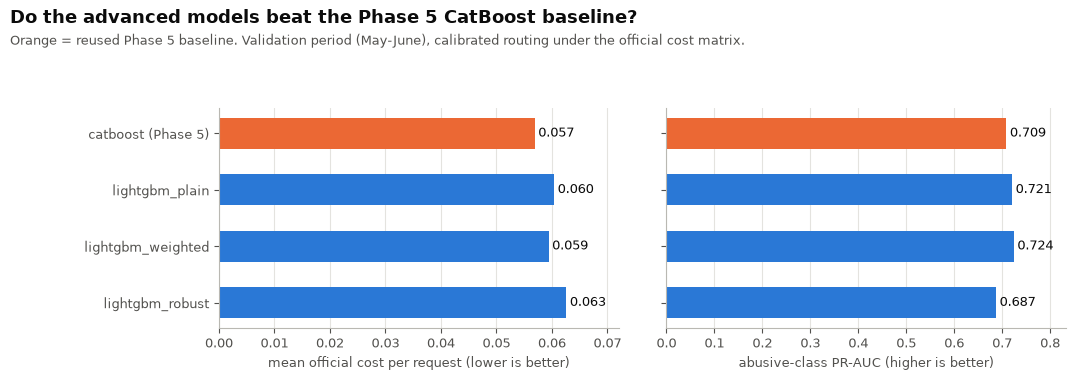

In [10]:
INK, MUTED, GRID, GREY = '#0b0b0b', '#52514e', '#e4e3df', '#b9b8b2'
BLUE, ORANGE = '#2a78d6', '#eb6834'

def style(ax, grid_axis='x'):
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(GREY)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

order = list(comparison.index)
colours = [ORANGE if name.startswith('catboost') else BLUE for name in order]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
fig.subplots_adjust(top=0.72, left=0.2, right=0.97, bottom=0.14, wspace=0.12)
for ax, column, label in ((axes[0], 'cost_per_request', 'mean official cost per request (lower is better)'), (axes[1], 'abusive_PR_AUC', 'abusive-class PR-AUC (higher is better)')):
    bars = ax.barh(order[::-1], comparison[column].to_numpy()[::-1], color=colours[::-1], height=0.55)
    for bar, value in zip(bars, comparison[column].to_numpy()[::-1]):
        ax.text(bar.get_width() + comparison[column].max() * 0.01, bar.get_y() + bar.get_height() / 2, f'{value:.3f}', va='center', fontsize=9, color=INK)
    ax.set_xlim(0, comparison[column].max() * 1.15)
    ax.set_xlabel(label, color=MUTED, fontsize=9)
    style(ax)
fig.text(0.01, 0.98, 'Do the advanced models beat the Phase 5 CatBoost baseline?', fontsize=13, fontweight='bold', color=INK, va='top')
fig.text(0.01, 0.915, 'Orange = reused Phase 5 baseline. Validation period (May-June), calibrated routing under the official cost matrix.', fontsize=9.5, color=MUTED, va='top')
fig.savefig(FIG / 'phase6_cost_and_pr_auc.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Verdict and the best advanced model
Rule (fixed beforehand, same as Phase 5): among the **advanced** models, rank by calibrated cost saving and take the simplest (plain, then weighted, then robust, then TabPFN) within max(seed sd, 0.005) of the best.
An advanced model counts as **clearly better** than the Phase 5 baseline only if its saving gain exceeds twice the larger seed sd **and** it does not escalate more genuine customers.

In [11]:
advanced = comparison.drop(index='catboost (Phase 5)')
best_name = advanced['saving'].idxmax()
tolerance = max(float(advanced.loc[best_name, 'saving_sd']), 0.005)
rank = {'lightgbm_plain': 0, 'lightgbm_weighted': 1, 'lightgbm_robust': 2, 'tabpfn': 3}
eligible = advanced[advanced['saving'] >= advanced.loc[best_name, 'saving'] - tolerance]
best_advanced = min(eligible.index, key=lambda n: rank.get(n, 9))
base = comparison.loc['catboost (Phase 5)']
cand = comparison.loc[best_advanced]
gain = cand['saving'] - base['saving']
margin = 2 * max(cand['saving_sd'] if cand['saving_sd'] == cand['saving_sd'] else 0, base['saving_sd'], 0.005)
clearly_better = gain > margin and cand['genuine_escalated'] <= base['genuine_escalated'] + 0.5
print('best advanced model:', best_advanced)
print(f"saving {cand['saving']:.4f} vs CatBoost {base['saving']:.4f} (gain {gain:+.4f}, margin {margin:.4f}); official score {cand['official_score']:.3f} vs {base['official_score']:.3f}")
print(f"genuine escalated {cand['genuine_escalated']:.1f} vs {base['genuine_escalated']:.1f}; false-block rate {cand['genuine_false_block_rate']:.3f} vs {base['genuine_false_block_rate']:.3f}")
print('VERDICT:', 'clearly better than the Phase 5 baseline' if clearly_better else 'NOT clearly better than the Phase 5 baseline (keep CatBoost as the reference)')

best advanced model: lightgbm_weighted
saving 0.2785 vs CatBoost 0.3089 (gain -0.0304, margin 0.0196); official score 0.303 vs 0.363
genuine escalated 3.5 vs 1.0; false-block rate 0.011 vs 0.020
VERDICT: NOT clearly better than the Phase 5 baseline (keep CatBoost as the reference)


## 9. Error analysis: confusion matrix of the best advanced model

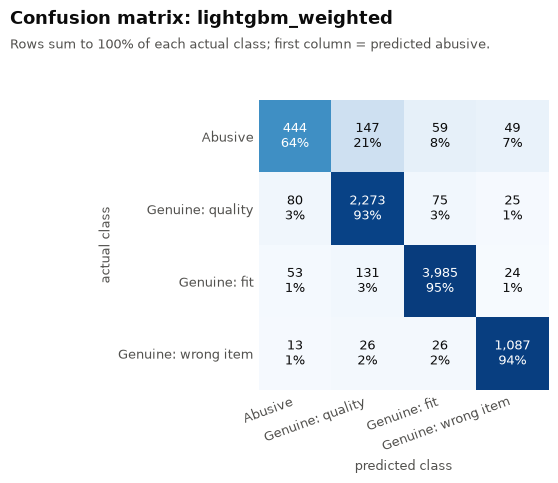

most frequent confusions (actual -> predicted):


,actual,predicted,count
0,Abusive,Genuine: quality,147
1,Genuine: fit,Genuine: quality,131
2,Genuine: quality,Abusive,80
3,Genuine: quality,Genuine: fit,75
4,Abusive,Genuine: fit,59
5,Genuine: fit,Abusive,53


In [12]:
report = store[(best_advanced, 0)]['report']
cm = report['confusion']
names = {'abusive': 'Abusive', 'genuine_quality_issue': 'Genuine: quality', 'genuine_fit_issue': 'Genuine: fit', 'genuine_wrong_item': 'Genuine: wrong item'}
row_share = cm.div(cm.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(6.4, 5.0))
fig.subplots_adjust(top=0.8, left=0.3, right=0.95, bottom=0.22)
ax.imshow(row_share.to_numpy(), cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(4))
ax.set_xticklabels([names[l] for l in LABELS], rotation=20, ha='right', fontsize=9)
ax.set_yticks(range(4))
ax.set_yticklabels([names[l] for l in LABELS], fontsize=9)
ax.set_xlabel('predicted class', color=MUTED, fontsize=9)
ax.set_ylabel('actual class', color=MUTED, fontsize=9)
for i in range(4):
    for j in range(4):
        value = row_share.iat[i, j]
        ax.text(j, i, f'{cm.iat[i, j]:,}\n{value:.0%}', ha='center', va='center', fontsize=9, color='white' if value > 0.55 else INK)
for side in ax.spines.values():
    side.set_visible(False)
ax.tick_params(colors=MUTED, length=0)
fig.text(0.01, 0.98, f'Confusion matrix: {best_advanced}', fontsize=13, fontweight='bold', color=INK, va='top')
fig.text(0.01, 0.925, 'Rows sum to 100% of each actual class; first column = predicted abusive.', fontsize=9.5, color=MUTED, va='top')
fig.savefig(FIG / 'phase6_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
pairs = [(names[a], names[b], int(cm.loc[f'true_{a}', f'pred_{b}'])) for a in LABELS for b in LABELS if a != b]
print('most frequent confusions (actual -> predicted):')
pd.DataFrame(sorted(pairs, key=lambda t: -t[2])[:6], columns=['actual', 'predicted', 'count'])

## 10. Feature importance
Gain-based importance of the best LightGBM variant (tree models only; TabPFN does not provide this). Top 15 features, shares sum to 1 over all features.

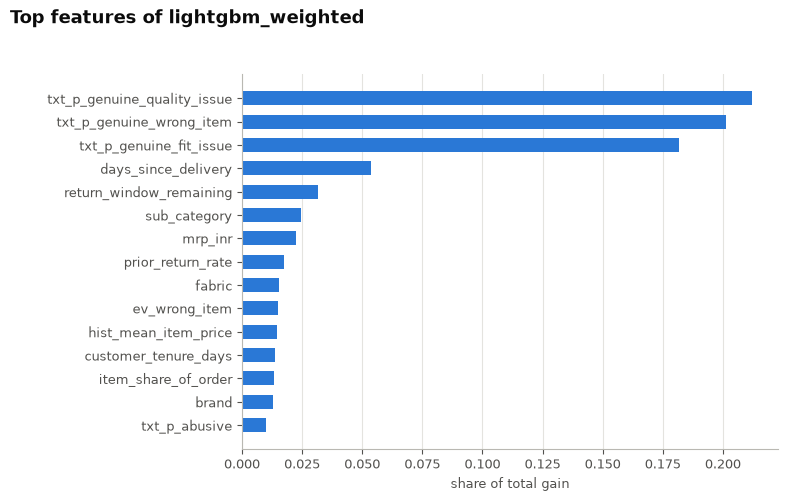

,gain_share
txt_p_genuine_quality_issue,0.2123
txt_p_genuine_wrong_item,0.2012
txt_p_genuine_fit_issue,0.1817
days_since_delivery,0.0535
return_window_remaining,0.0316
sub_category,0.0246
mrp_inr,0.0226
prior_return_rate,0.0174
fabric,0.0155
ev_wrong_item,0.0150


In [13]:
lgbm_best = best_advanced.replace('lightgbm_', '') if best_advanced.startswith('lightgbm') else min(
    (v for v in lgbm_models), key=lambda v: -comparison.loc[f'lightgbm_{v}', 'saving'])
top = importance_table(lgbm_models[lgbm_best], list(x_train.columns), top=15)
fig, ax = plt.subplots(figsize=(8, 5))
fig.subplots_adjust(top=0.85, left=0.3, right=0.97, bottom=0.1)
ax.barh(top.index[::-1], top['gain_share'].to_numpy()[::-1], color=BLUE, height=0.6)
style(ax)
ax.set_xlabel('share of total gain', color=MUTED, fontsize=9)
fig.text(0.01, 0.98, f'Top features of lightgbm_{lgbm_best}', fontsize=13, fontweight='bold', color=INK, va='top')
fig.savefig(FIG / 'phase6_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
top.to_csv(REPORTS / 'phase6_feature_importance.csv')
top

## 11. Temporal stability (May vs June)
The validation period is split by month. Calibration and all models are unchanged; only the evaluation rows differ.

In [14]:
month = parts['test']['return_request_date'].dt.to_period('M').astype(str).to_numpy()
rows = []
for (name, seed), item in store.items():
    if seed != 0:
        continue
    for m in sorted(set(month)):
        mask = month == m
        y_m = y_abuse['test'][mask]
        if y_m.sum() == 0:
            continue
        cost = business_cost(item['cal'][mask], y_m, cfg)
        rows.append({'model': name, 'month': m, 'rows': int(mask.sum()), 'abusive_PR_AUC': average_precision_score(y_m, item['raw'][mask]),
                     'saving': cost['saving_vs_approve_all'], 'genuine_escalated': cost['genuine_escalated']})
stability = pd.DataFrame(rows).pivot(index='model', columns='month', values=['abusive_PR_AUC', 'saving']).round(3)
stability.to_csv(REPORTS / 'phase6_temporal_stability.csv')
stability

abusive_PR_AUC          saving        
month                     2026-05 2026-06 2026-05 2026-06
model                                                    
catboost (Phase 5)          0.728   0.695   0.318   0.301
lightgbm_plain              0.749   0.702   0.308   0.295
lightgbm_robust             0.723   0.662   0.267   0.207
lightgbm_weighted           0.751   0.707   0.299   0.265

## 12. Save artifacts, predictions and configuration

In [15]:
for variant, model in lgbm_models.items():
    model.booster_.save_model(str(MODELS / f'lightgbm_{variant}_seed0.txt'))
predictions = parts['test'][['return_id', 'label']].reset_index(drop=True)
for (name, seed), item in store.items():
    if seed == 0:
        predictions[f'{name}|p_abusive_raw'] = item['raw']
        predictions[f'{name}|p_abusive_calibrated'] = item['cal']
best_probs = store[(best_advanced, 0)]['probs']
for index, label in enumerate(LABELS):
    predictions[f'{best_advanced}|p_{label}'] = best_probs[:, index]
predictions.to_csv(REPORTS / 'phase6_validation_predictions.csv', index=False)
tabpfn_status = globals().get('tabpfn_status', {'outcome': 'TabPFN cell not present in this run'})
xgboost_status = globals().get('xgboost_status', {'installed': False})
record = {'best_advanced_model': best_advanced, 'clearly_better_than_phase5_catboost': bool(clearly_better),
          'selection_rule': 'simplest advanced model within max(seed sd, 0.005) of the best calibrated saving; clear gain needs > 2x seed sd and no more genuine escalations',
          'protocol': 'Phase 2 chronological 70/10/20; calibration part fits only the isotonic calibrator; test = May-June validation period',
          'features': 'arm C: structured (Phase 3 preprocessor fitted on train) + Phase 4 rolling-origin text scores + rule/shape + text reuse',
          'seeds': list(SEEDS), 'lightgbm_variants': {v: m.get_params() for v, m in lgbm_models.items()},
          'tabpfn': tabpfn_status, 'xgboost': xgboost_status, 'catboost': 'reused from Phase 5, not retrained',
          'hidden_test_labels_used': False, 'versions': versions}
(REPORTS / 'phase6_config.json').write_text(json.dumps(record, indent=2, default=str))
print(sorted(p.name for p in REPORTS.glob('phase6_*')), '|', sorted(p.name for p in MODELS.glob('*')))

['phase6_config.json', 'phase6_feature_importance.csv', 'phase6_model_comparison.csv', 'phase6_temporal_stability.csv', 'phase6_validation_predictions.csv'] | ['lightgbm_plain_seed0.txt', 'lightgbm_robust_seed0.txt', 'lightgbm_weighted_seed0.txt']


## 13. Limitations
- One validation window; differences smaller than the seed spread (see `saving_sd`) are not evidence of a real difference.
- Model choices and the selection rule use the same window that is reported, so the winner's numbers are slightly optimistic.
- LightGBM variants are fixed configurations, not tuned. A tuned model could change the ordering, but tuning on this window would add more optimism.
- TabPFN, if run, trains on a stratified sub-sample (at most `TABPFN_MAX_TRAIN_ROWS` rows) and uses one seed, so it is not trained on identical rows to the other models.
- CatBoost is the single reused Phase 5 run; its sd comes from Phase 5's two seeds.
- Memory is approximate process growth; inference time excludes calibration and routing.
- Ensembles are deliberately left to Phase 7.

## 14. Completion checklist

In [16]:
checklist = {
    'Same features and validation period across models': True,
    'TabPFN trained or limitation recorded': tabpfn_status['outcome'] != '',
    'Robust gradient boosting trained': {'lightgbm_plain', 'lightgbm_weighted', 'lightgbm_robust'} <= set(comparison.index),
    'CatBoost reused from Phase 5, not duplicated': 'catboost (Phase 5)' in comparison.index,
    'Class distribution reported': len(distribution) == 4,
    'Cost, PR-AUC, precision and recall compared': {'cost_per_request', 'abusive_PR_AUC', 'abusive_precision', 'abusive_recall'} <= set(comparison.columns),
    'Genuine-customer false-block rate reported': 'genuine_false_block_rate' in comparison,
    'Confusion matrix for the best advanced model': (FIG / 'phase6_confusion_matrix.png').exists(),
    'Feature importance reported': (REPORTS / 'phase6_feature_importance.csv').exists(),
    'Training time, inference time and memory reported': {'train_s', 'infer_ms_per_1k', 'rss_mb'} <= set(comparison.columns),
    'Temporal stability reported': (REPORTS / 'phase6_temporal_stability.csv').exists(),
    'Artifacts, predictions and configuration saved': (REPORTS / 'phase6_config.json').exists(),
    'No ensemble built': True,
    'July-September labels untouched': 'label' not in data['test'].columns,
}
not_done = [k for k, v in checklist.items() if not v]
assert not not_done, not_done
print('all', len(checklist), 'items done')

all 14 items done
